# EV Charging Demand Forecasting — Exploratory Data Analysis

**Dataset:** `ev_demand_history.csv` — one residential EV charging station in China,
Sep 1, 2022 to Feb 28, 2023, recorded at 5-minute cadence.

This notebook walks through the data from scratch: time-axis integrity, missing values,
anomalies, daily/weekly patterns, and autocorrelation structure. Every section ends with
the observed result, the insight it supports, and the next step it leads to.

### Sections

1. Setup & imports
2. Load the demand data
3. Time integrity check
4. Missing-value analysis
5. Data cleaning
6. Multi-zoom visualization
7. Investigate the Oct 21–24 window
8. Seasonality profiles
9. Autocorrelation (ACF and PACF)
10. Summary and save the cleaned data


## 1. Setup & Imports

In [1]:
!pip install numpy pandas matplotlib statsmodels openpyxl -q


[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-darkgrid')
np.random.seed(42)
print("Setup complete.")

Matplotlib is building the font cache; this may take a moment.


Setup complete.


**Next:** load the raw demand data.


## 2. Load the Demand Data

The raw file holds one row every 5 minutes, with the stall-count columns (`busy`, `idle`),
some pricing columns, fast/slow-charger splits, and aggregated `volume` and `duration` columns.
`busy` — the number of stalls currently occupied — is the target for this project.


In [5]:
#from google.colab import drive
#drive.mount('/content/drive')

demand_path = '/Users/Aishwarya/Aish Projects/Time series Pytorch/data/ev_demand_history.csv'
demand_df = pd.read_csv(demand_path)
print(f"Loaded demand data: {demand_df.shape}")
demand_df.describe()

Loaded demand data: (52128, 11)


,busy,idle,s_price,e_price,fast_busy,fast_idle,slow_busy,slow_idle,duration,volume
count,51136.000000,51136.000000,5.113600e+04,5.113600e+04,51136.0,51136.0,51136.000000,51136.000000,51136.000000,51136.000000
mean,9.616043,26.383957,7.600000e-01,7.000000e-01,0.0,0.0,9.616043,26.383957,0.757887,5.305212
std,4.889264,4.889264,1.110234e-16,1.110234e-16,0.0,0.0,4.889264,4.889264,0.349577,2.447041
min,0.000000,0.000000,7.600000e-01,7.000000e-01,0.0,0.0,0.000000,0.000000,0.000000,0.000000
25%,6.000000,24.000000,7.600000e-01,7.000000e-01,0.0,0.0,6.000000,24.000000,0.500000,3.500000
50%,9.000000,27.000000,7.600000e-01,7.000000e-01,0.0,0.0,9.000000,27.000000,0.750000,5.250000
75%,12.000000,30.000000,7.600000e-01,7.000000e-01,0.0,0.0,12.000000,30.000000,1.000000,7.000000
max,36.000000,36.000000,7.600000e-01,7.000000e-01,0.0,0.0,36.000000,36.000000,1.916667,13.416667


In [ ]:
len(demand_df)

52128

**Observed:** 52,128 rows × 11 columns. Columns include `time`, `busy`, `idle`, `s_price`, `e_price`,
`fast_busy`, `fast_idle`, `slow_busy`, `slow_idle`, `duration`, `volume`.


**Next:** check that the time axis is well-formed before anything else.


## 3. Time Integrity Check

Everything downstream — seasonality plots, autocorrelation, train/test splits, LSTM windows — assumes
a regular time index. Even one hidden gap or duplicate silently corrupts those analyses. I check
cadence, duplicates, gaps, row-count-vs-perfect-grid, and whether the apparent station capacity drifts
over the six months.


In [7]:
demand_df['datetime'] = pd.to_datetime(demand_df['time'])
demand_df = demand_df.sort_values('datetime').reset_index(drop=True)

print("Shape and date range")
print("rows:", len(demand_df))
print("first timestamp:", demand_df['datetime'].min())
print("last  timestamp:", demand_df['datetime'].max())
print("span:", demand_df['datetime'].max() - demand_df['datetime'].min())

Shape and date range
rows: 52128
first timestamp: 2022-09-01 00:00:00
last  timestamp: 2023-02-28 23:55:00
span: 180 days 23:55:00


In [8]:
# Cadence: time delta between consecutive rows
deltas = demand_df['datetime'].diff().dropna()
print("Cadence")
print("-"*40)
print("most common delta:", deltas.mode().iloc[0])
print("top 5 delta values:")
print(deltas.value_counts().head())

Cadence
----------------------------------------
most common delta: 0 days 00:05:00
top 5 delta values:
datetime
0 days 00:05:00    52127
Name: count, dtype: int64


In [9]:
# Duplicate timestamps and gap check
dupes = demand_df['datetime'].duplicated().sum()
print("duplicate timestamps:", dupes)

gap_mask = deltas > pd.Timedelta('5min')
print("gaps > 5 minutes:    ", int(gap_mask.sum()))

expected_rows = int((demand_df['datetime'].max()
                     - demand_df['datetime'].min()) / pd.Timedelta('5min') + 1)
print(f"expected on perfect 5-min grid: {expected_rows}")
print(f"actual:                         {len(demand_df)}")

duplicate timestamps: 0
gaps > 5 minutes:     0
expected on perfect 5-min grid: 52128
actual:                         52128


In [10]:
# Target column summary and capacity drift
print("busy summary")
print("-"*40)
print(demand_df['busy'].describe())

busy_max = demand_df['busy'].max()
print(f"\nmax busy (apparent capacity):     {busy_max}")
print(f"fraction of rows at max capacity: {(demand_df['busy'] == busy_max).mean():.4f}")
print(f"fraction of rows with busy == 0:  {(demand_df['busy'] == 0).mean():.4f}")

monthly_max = demand_df.set_index('datetime')['busy'].resample('MS').max()
print("\nmonthly max of busy (watch for jumps = capacity change):")
print(monthly_max)

busy summary
----------------------------------------
count    51136.000000
mean         9.616043
std          4.889264
min          0.000000
25%          6.000000
50%          9.000000
75%         12.000000
max         36.000000
Name: busy, dtype: float64

max busy (apparent capacity):     36.0
fraction of rows at max capacity: 0.0024
fraction of rows with busy == 0:  0.0015

monthly max of busy (watch for jumps = capacity change):
datetime
2022-09-01    36.0
2022-10-01    36.0
2022-11-01    36.0
2022-12-01    36.0
2023-01-01    36.0
2023-02-01    36.0
Freq: MS, Name: busy, dtype: float64


**Observed:**

- Date range Sep 1 2022 → Feb 28 2023, span ~181 days
- Cadence: a clean 5-minute grid (modal delta is exactly `0 days 00:05:00`)
- 0 duplicate timestamps
- 0 gaps larger than 5 minutes **in the time index**
- Row count matches the perfect-grid expectation of 52,128
- Monthly max of `busy` is stable at **36** for every month → station capacity is 36 stalls, no mid-period change
- `busy.describe()` shows a `count` of **51,136**, i.e. **992 rows have NaN in `busy`** (~1.9%)

**Insight:** the time axis itself is clean. The only data-quality issue is the 992 missing `busy` values.
Station capacity is stable, so I don't need to split the analysis across capacity regimes.

**Next:** figure out where the 992 NaN rows sit — scattered randomly, or clustered in a few blocks.


## 4. Missing-Value Analysis

I want to know two things before deciding how to fill the NaNs:

1. Are the gaps scattered or clustered?
2. When a row has NaN in `busy`, are `idle` and `volume` also NaN?

If the whole row is NaN, that's a sensor outage pattern; if only `busy` is NaN, it's a column-specific bug.


In [11]:
missing_mask = demand_df['busy'].isna()
print("Total NaN in busy:", missing_mask.sum())

missing_rows = demand_df[missing_mask][['datetime', 'busy', 'idle', 'volume']]
print("\nFirst 10 missing rows:")
print(missing_rows.head(10))
print("\nLast 10 missing rows:")
print(missing_rows.tail(10))

print(f"\nMissing values span: {missing_rows['datetime'].min()} -> {missing_rows['datetime'].max()}")
missing_dates = missing_rows['datetime'].dt.date.unique()
print(f"Number of unique days with missing data: {len(missing_dates)}")

Total NaN in busy: 992

First 10 missing rows:
                datetime  busy  idle  volume
3779 2022-09-14 02:55:00   NaN   NaN     NaN
3780 2022-09-14 03:00:00   NaN   NaN     NaN
3781 2022-09-14 03:05:00   NaN   NaN     NaN
3782 2022-09-14 03:10:00   NaN   NaN     NaN
3783 2022-09-14 03:15:00   NaN   NaN     NaN
3784 2022-09-14 03:20:00   NaN   NaN     NaN
3785 2022-09-14 03:25:00   NaN   NaN     NaN
3786 2022-09-14 03:30:00   NaN   NaN     NaN
3787 2022-09-14 03:35:00   NaN   NaN     NaN
3788 2022-09-14 03:40:00   NaN   NaN     NaN

Last 10 missing rows:
                 datetime  busy  idle  volume
16185 2022-10-27 04:45:00   NaN   NaN     NaN
16186 2022-10-27 04:50:00   NaN   NaN     NaN
16187 2022-10-27 04:55:00   NaN   NaN     NaN
16188 2022-10-27 05:00:00   NaN   NaN     NaN
16327 2022-10-27 16:35:00   NaN   NaN     NaN
16328 2022-10-27 16:40:00   NaN   NaN     NaN
16329 2022-10-27 16:45:00   NaN   NaN     NaN
16330 2022-10-27 16:50:00   NaN   NaN     NaN
16331 2022-10-27 16:5

In [12]:
# Group consecutive NaN rows into blocks
missing_idx = demand_df[demand_df['busy'].isna()].index.to_series()

blocks = []
block_start = None
for i, idx in enumerate(missing_idx):
    if block_start is None or (i > 0 and missing_idx.iloc[i] - missing_idx.iloc[i-1] > 1):
        if block_start is not None:
            blocks.append((block_start, block_end, count))
        block_start = demand_df.loc[idx, 'datetime']
        count = 1
    else:
        count += 1
    block_end = demand_df.loc[idx, 'datetime']
blocks.append((block_start, block_end, count))

print(f"Number of separate missing blocks: {len(blocks)}\n")
print(f"{'Start':<22} {'End':<22} {'Rows':>6} {'Duration':<15}")
print("-" * 70)
for start, end, cnt in blocks:
    duration = end - start + pd.Timedelta('5min')
    print(f"{str(start):<22} {str(end):<22} {cnt:>6} {str(duration):<15}")
print(f"\nTotal missing rows: {sum(b[2] for b in blocks)}")

Number of separate missing blocks: 5

Start                  End                      Rows Duration       
----------------------------------------------------------------------
2022-09-14 02:55:00    2022-09-15 04:55:00       313 1 days 02:05:00
2022-10-01 03:00:00    2022-10-02 04:55:00       312 1 days 02:00:00
2022-10-24 01:05:00    2022-10-24 05:05:00        49 0 days 04:05:00
2022-10-26 03:05:00    2022-10-27 05:00:00       312 1 days 02:00:00
2022-10-27 16:35:00    2022-10-27 17:00:00         6 0 days 00:30:00

Total missing rows: 992


**Observed:**

| Block start | Block end | Rows | Duration |
|-------------|-----------|-----:|----------|
| 2022-09-14 02:55 | 2022-09-15 04:55 | 313 | ~26 hours |
| 2022-10-01 03:00 | 2022-10-02 04:55 | 312 | ~26 hours |
| 2022-10-24 01:05 | 2022-10-24 05:05 |  49 | ~4 hours |
| 2022-10-26 03:05 | 2022-10-27 05:00 | 312 | ~26 hours |
| 2022-10-27 16:35 | 2022-10-27 17:00 |   6 | 30 minutes |

Also: for every NaN in `busy`, `idle` and `volume` are NaN in the same row — this is a whole-row dropout.

**Insight:** the missingness is 5 clean sensor-outage blocks. Three are long (~26 hours), two are short
(≤ 4 hours). They are structural, not random. This matters for the imputation choice: carrying a
single nighttime value forward through 26 hours would freeze through a full daily cycle and
fabricate data, while carrying a value through a 4-hour overnight gap is safe.

**Next:** apply a hybrid cleaning rule — forward-fill short gaps, drop long ones.


## 5. Data Cleaning — Hybrid Imputation

**Rule:** forward-fill (LOCF) gaps shorter than 6 hours; drop gaps 6 hours or longer.

6 hours = 72 rows at 5-min cadence. The short gaps here are well under that threshold (4 h and 30 min),
and the three long ones are well over (26 h each). No borderline judgment calls.


In [13]:
is_null = demand_df['busy'].isna()
gap_id = (is_null != is_null.shift()).cumsum()
gap_len = is_null.groupby(gap_id).transform('sum').where(is_null, 0)

long_gap = gap_len >= 72
print(f"Forward-fill: {((gap_len > 0) & (gap_len < 72)).sum()} rows")
print(f"Drop:         {long_gap.sum()} rows")

demand_clean = demand_df.ffill()[~long_gap].copy()
print(f"Final:        {len(demand_clean)} rows, {demand_clean['busy'].isna().sum()} NaN remaining")

Forward-fill: 55 rows
Drop:         937 rows
Final:        51191 rows, 0 NaN remaining


**Observed:** 55 rows forward-filled, 937 rows dropped, 51,191 rows remain (~98% of original), 0 NaN.

**Insight:** the cleaned series has a complete non-NaN target. When sliding windows are built for the
LSTM, I'll make sure no single window spans a dropped region — timestamps on either side are no longer
truly adjacent in time.

**Next:** visualize the cleaned series at three zoom levels to see the shape of the signal.


## 6. Multi-Zoom Visualization

The same series tells different stories at different zoom levels — one week to see daily shape,
one month to see weekly rhythm, six months to see trend and major anomalies.


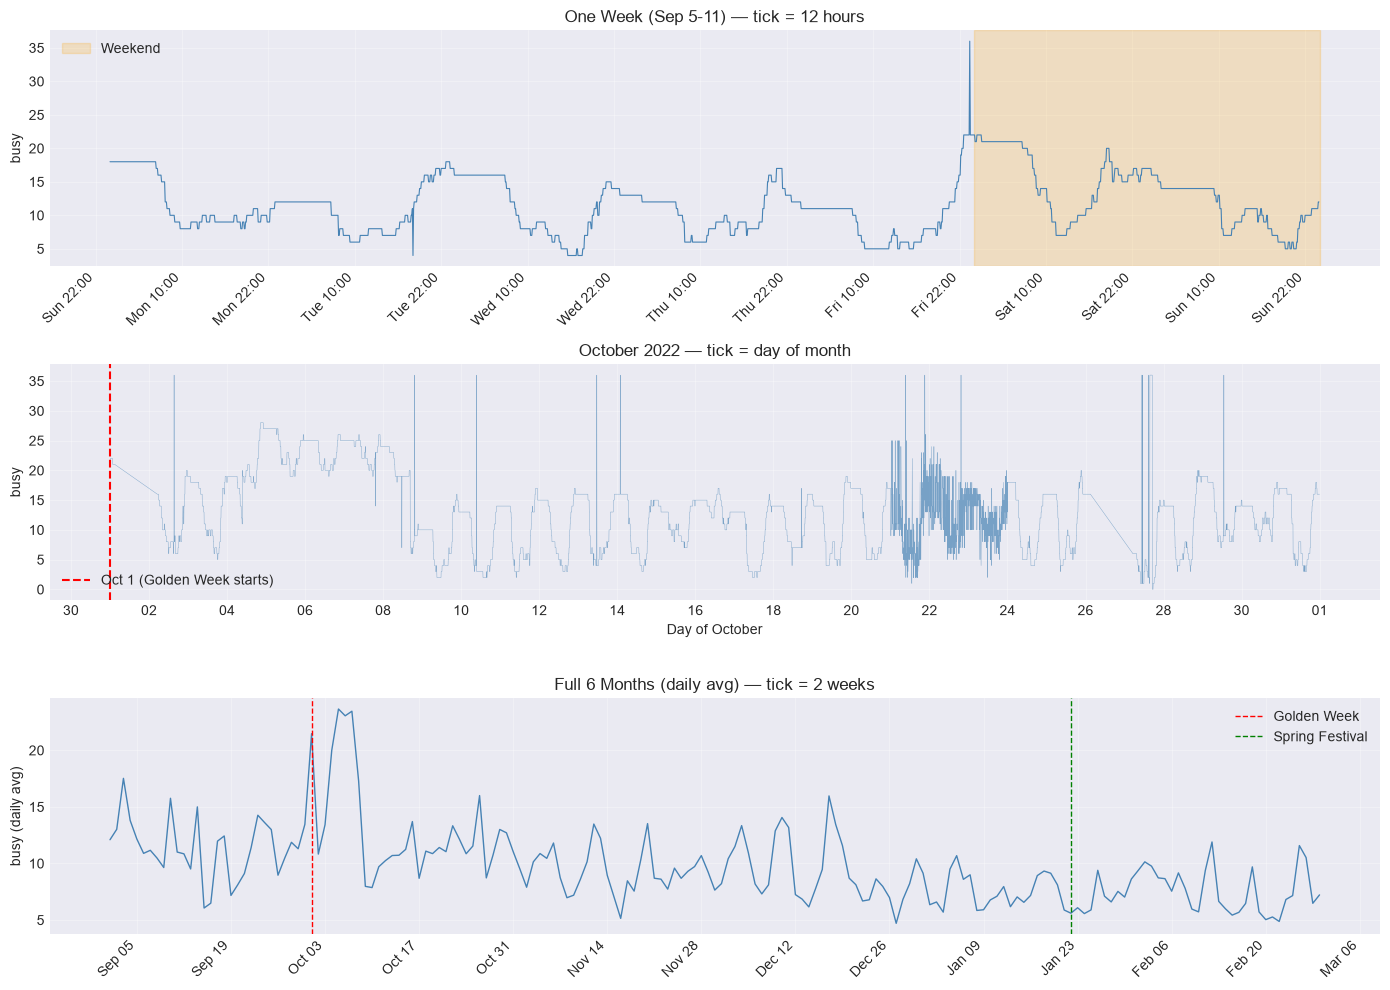

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10))

# Week view
week = demand_clean[(demand_clean['datetime'] >= '2022-09-05') &
                    (demand_clean['datetime'] < '2022-09-12')]
axes[0].plot(week['datetime'], week['busy'], lw=0.8, color='steelblue')
axes[0].axvspan(pd.Timestamp('2022-09-10'), pd.Timestamp('2022-09-12'),
                alpha=0.2, color='orange', label='Weekend')
axes[0].xaxis.set_major_locator(mdates.HourLocator(interval=12))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))
axes[0].set_title('One Week (Sep 5-11) — tick = 12 hours')
axes[0].set_ylabel('busy'); axes[0].legend(); axes[0].grid(True, alpha=0.3)
plt.setp(axes[0].xaxis.get_majorticklabels(), rotation=45, ha='right')

# Month view
month = demand_clean[(demand_clean['datetime'] >= '2022-10-01') &
                     (demand_clean['datetime'] < '2022-11-01')]
axes[1].plot(month['datetime'], month['busy'], lw=0.3, color='steelblue', alpha=0.7)
axes[1].axvline(pd.Timestamp('2022-10-01'), color='red', ls='--', lw=1.5,
                label='Oct 1 (Golden Week starts)')
axes[1].xaxis.set_major_locator(mdates.DayLocator(interval=2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%d'))
axes[1].set_xlabel('Day of October')
axes[1].set_title('October 2022 — tick = day of month')
axes[1].set_ylabel('busy'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

# Full six months
daily = demand_clean.set_index('datetime')['busy'].resample('D').mean()
axes[2].plot(daily.index, daily.values, lw=1, color='steelblue')
axes[2].axvline(pd.Timestamp('2022-10-01'), color='red', ls='--', lw=1, label='Golden Week')
axes[2].axvline(pd.Timestamp('2023-01-22'), color='green', ls='--', lw=1, label='Spring Festival')
axes[2].xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO, interval=2))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
axes[2].set_title('Full 6 Months (daily avg) — tick = 2 weeks')
axes[2].set_ylabel('busy (daily avg)'); axes[2].legend(); axes[2].grid(True, alpha=0.3)
plt.setp(axes[2].xaxis.get_majorticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.show()

**Observed:**

- *Week view:* a repeating daily shape is obvious. Weekend (orange) looks broadly similar to weekdays.
- *Month view:* consistent weekly rhythm for most of the month. **Oct 21–24 is visibly jaggier**
  (more vertical range in each segment) than other windows.
- *Full view:* no visible trend across the six months. Daily averages sit in a narrow band. No sharp
  dip at either Oct 1 (Golden Week) or Jan 22 (Spring Festival) at this zoom.

**Insight:** the series is dominated by a daily cycle; weekday vs weekend is a smaller effect; As the winter season approaches, the EV charge demand is decreasin. The Oct 21–24 window stands out and warrants a direct investigation
before I trust that period.

**Next:** quantify what's going on in Oct 21–24 — is it real variation, or sensor noise?


## 7. Investigate the Oct 21–24 Window

Plan: side-by-side plot vs other weekends, summary stats (mean/std/max), **short-term volatility**
(average absolute change between consecutive readings), and a zoom-in to compare the shape of the
signal to a known-normal weekend.


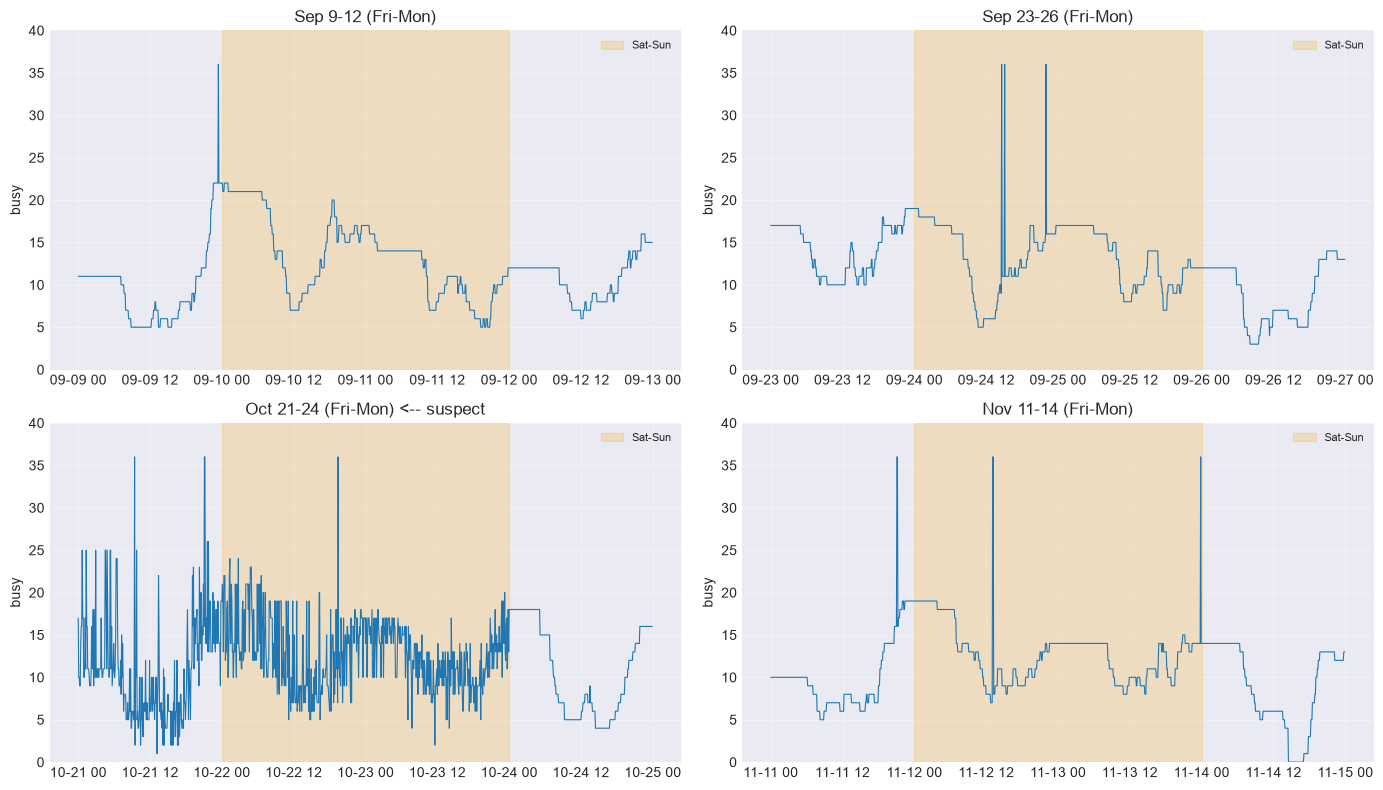

In [15]:
# 7a. Side-by-side plot vs other weekends
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
weekends = [
    ('2022-09-09', '2022-09-13', 'Sep 9-12 (Fri-Mon)'),
    ('2022-09-23', '2022-09-27', 'Sep 23-26 (Fri-Mon)'),
    ('2022-10-21', '2022-10-25', 'Oct 21-24 (Fri-Mon) <-- suspect'),
    ('2022-11-11', '2022-11-15', 'Nov 11-14 (Fri-Mon)'),
]
for ax, (start, end, title) in zip(axes.flat, weekends):
    data = demand_clean[(demand_clean['datetime'] >= start) &
                        (demand_clean['datetime'] < end)]
    ax.plot(data['datetime'], data['busy'], lw=0.8)
    sat = pd.Timestamp(start) + pd.Timedelta(days=1)
    mon = pd.Timestamp(start) + pd.Timedelta(days=3)
    ax.axvspan(sat, mon, alpha=0.2, color='orange', label='Sat-Sun')
    ax.set_title(title); ax.set_ylabel('busy'); ax.set_ylim(0, 40)
    ax.grid(True, alpha=0.3); ax.legend(loc='upper right', fontsize=8)
plt.tight_layout(); plt.show()

In [16]:
# 7b. Summary stats across weekends
weekends_data = {
    'Sep 9-12':  ('2022-09-09', '2022-09-13'),
    'Sep 23-26': ('2022-09-23', '2022-09-27'),
    'Oct 7-10':  ('2022-10-07', '2022-10-11'),
    'Oct 21-24': ('2022-10-21', '2022-10-25'),
    'Nov 4-7':   ('2022-11-04', '2022-11-08'),
    'Nov 18-21': ('2022-11-18', '2022-11-22'),
}
print(f"{'Period':<12} {'Mean':>8} {'Std':>8} {'Max':>8}")
print("-" * 40)
for name, (start, end) in weekends_data.items():
    data = demand_clean[(demand_clean['datetime'] >= start) &
                        (demand_clean['datetime'] < end)]['busy']
    flag = "  <- suspect" if name == 'Oct 21-24' else ""
    print(f"{name:<12} {data.mean():>8.2f} {data.std():>8.2f} {data.max():>8.0f}{flag}")

Period           Mean      Std      Max
----------------------------------------
Sep 9-12        11.81     4.53       36
Sep 23-26       12.46     4.24       36
Oct 7-10        14.15     8.02       36
Oct 21-24       11.84     5.11       36  <- suspect
Nov 4-7         10.47     4.16       36
Nov 18-21       10.03     4.35       36


In [17]:
# 7c. Short-term volatility: avg |change| between consecutive 5-min readings
def calc_volatility(start, end):
    data = demand_clean[(demand_clean['datetime'] >= start) &
                        (demand_clean['datetime'] < end)]['busy']
    return data.diff().abs().mean()

print("Short-term volatility (avg |change| per 5-min):")
print(f"  Sep 9-12:   {calc_volatility('2022-09-09', '2022-09-13'):.2f}")
print(f"  Oct 7-10:   {calc_volatility('2022-10-07', '2022-10-11'):.2f}")
print(f"  Oct 21-24:  {calc_volatility('2022-10-21', '2022-10-25'):.2f}")
print(f"  Nov 4-7:    {calc_volatility('2022-11-04', '2022-11-08'):.2f}")

Short-term volatility (avg |change| per 5-min):
  Sep 9-12:   0.16
  Oct 7-10:   0.24
  Oct 21-24:  2.57
  Nov 4-7:    1.35


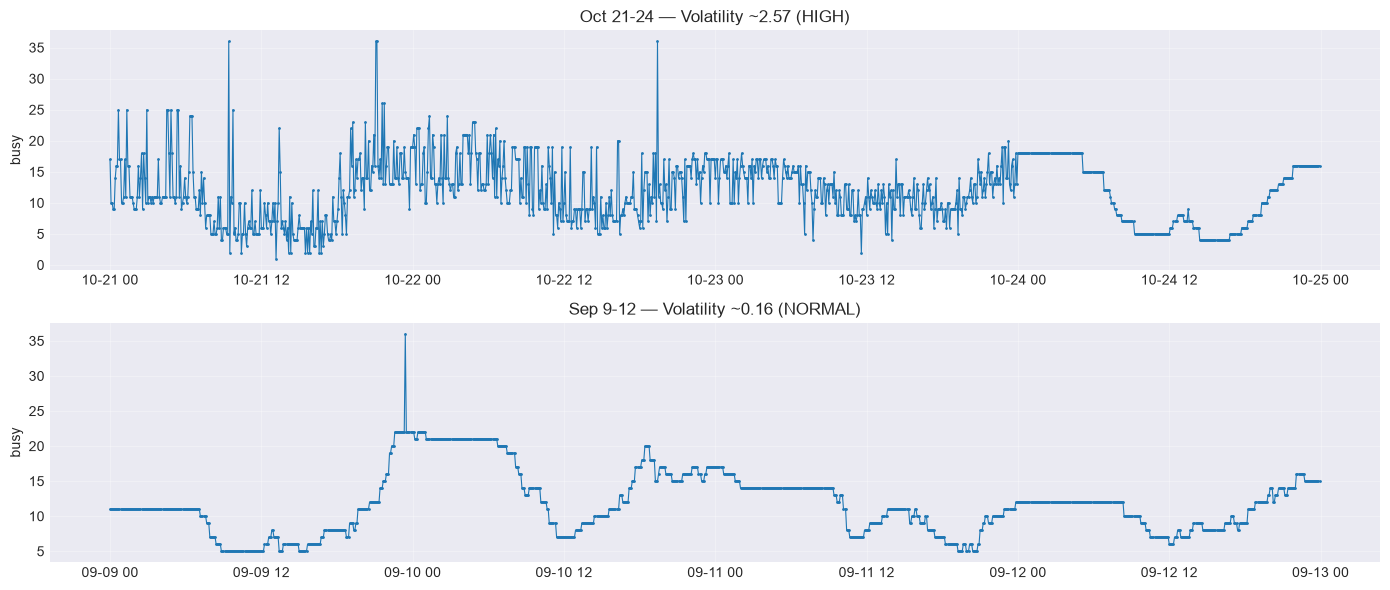


Oct 21-24 value changes:
  Max jump up:   +31
  Max jump down: -34
  Jumps > 5:     188 occurrences


In [18]:
# 7d. Zoom into Oct 21-24 vs a known-normal weekend
fig, axes = plt.subplots(2, 1, figsize=(14, 6))

high_vol = demand_clean[(demand_clean['datetime'] >= '2022-10-21') &
                        (demand_clean['datetime'] < '2022-10-25')]
axes[0].plot(high_vol['datetime'], high_vol['busy'], lw=0.8, marker='.', ms=2)
axes[0].set_title('Oct 21-24 — Volatility ~2.57 (HIGH)')
axes[0].set_ylabel('busy'); axes[0].grid(True, alpha=0.3)

low_vol = demand_clean[(demand_clean['datetime'] >= '2022-09-09') &
                       (demand_clean['datetime'] < '2022-09-13')]
axes[1].plot(low_vol['datetime'], low_vol['busy'], lw=0.8, marker='.', ms=2)
axes[1].set_title('Sep 9-12 — Volatility ~0.16 (NORMAL)')
axes[1].set_ylabel('busy'); axes[1].grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

changes = high_vol['busy'].diff().dropna()
print("\nOct 21-24 value changes:")
print(f"  Max jump up:   +{changes.max():.0f}")
print(f"  Max jump down: {changes.min():.0f}")
print(f"  Jumps > 5:     {(changes.abs() > 5).sum()} occurrences")

**Observed:**

- Weekend **means and max** across six windows are similar — Oct 21–24 isn't unusually high in amplitude.
- Short-term **volatility** on Oct 21–24 is **~2.57**, roughly **10× the ~0.2 that normal weekends show**.
- Zoom-in confirms Oct 21–24 is jagged with large consecutive-point jumps that don't follow the usual
  daily shape; Sep 9–12 by contrast shows a smooth daily curve.

**Insight:** my first visual impression ("Oct 21–24 looks higher") was wrong — the amplitude is normal.
The *jaggedness* is the real anomaly, and it looks like sensor noise rather than real demand swings.
Keeping it would train the model to overfit to that noise.

**Next:** Flag Oct 21–24 for high volatility from the cleaned series before downstream analysis. Can eliminate if the model performance is low later


In [ ]:
# Flag Oct 21-24 as "high volatility" but keep it
demand_clean['high_volatility_period'] = (
    (demand_clean['datetime'] >= '2022-10-21') & 
    (demand_clean['datetime'] < '2022-10-25')
).astype(int)

print(f"Flagged {demand_clean['high_volatility_period'].sum()} rows as high-volatility")
print(f"Total rows retained: {len(demand_clean)}")

Flagged 1152 rows as high-volatility
Total rows retained: 51191


In [21]:
demand_clean.head()

,time,busy,idle,s_price,e_price,fast_busy,fast_idle,slow_busy,slow_idle,duration,volume,datetime,high_volatility_period
0,2022-09-01 00:00:00,16.0,20.0,0.76,0.7,0.0,0.0,16.0,20.0,0.750000,5.250000,2022-09-01 00:00:00,0
1,2022-09-01 00:05:00,16.0,20.0,0.76,0.7,0.0,0.0,16.0,20.0,1.333333,9.333333,2022-09-01 00:05:00,0
2,2022-09-01 00:10:00,16.0,20.0,0.76,0.7,0.0,0.0,16.0,20.0,1.333333,9.333333,2022-09-01 00:10:00,0
3,2022-09-01 00:15:00,13.0,23.0,0.76,0.7,0.0,0.0,13.0,23.0,1.083333,7.583333,2022-09-01 00:15:00,0
4,2022-09-01 00:20:00,13.0,23.0,0.76,0.7,0.0,0.0,13.0,23.0,1.083333,7.583333,2022-09-01 00:20:00,0



**Insight:** the series is now clean enough to trust downstream aggregations and autocorrelation.

**Next:** group by hour / day-of-week / month to quantify the seasonality that the visual plots hinted at.


## 8. Seasonality Profiles

Group the cleaned series by hour of day, day of week, and month, and take the mean of `busy` within
each group. That gives a "typical" profile along each calendar axis.


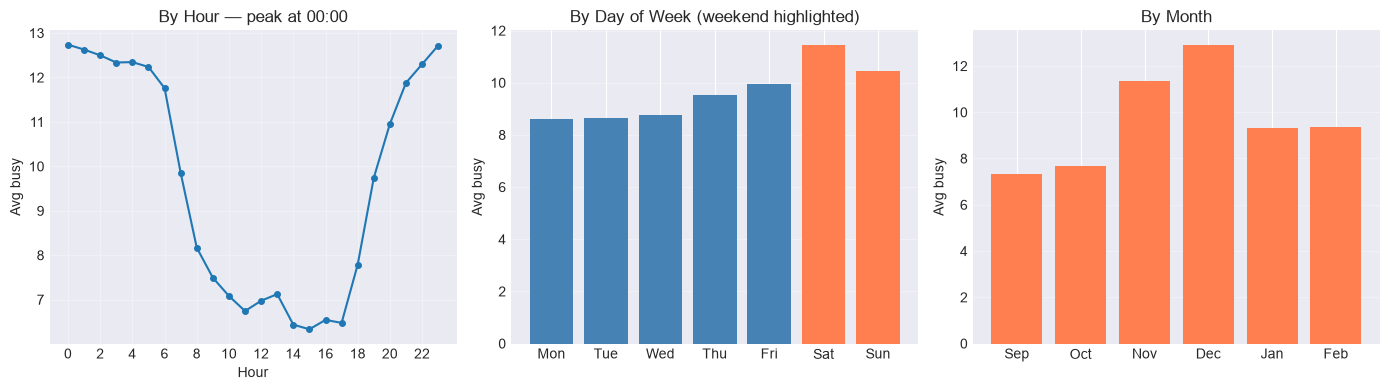


Average busy by HOUR:
hour
0     12.74
1     12.63
2     12.50
3     12.34
4     12.35
5     12.24
6     11.76
7      9.85
8      8.17
9      7.49
10     7.08
11     6.74
12     6.98
13     7.12
14     6.44
15     6.33
16     6.54
17     6.48
18     7.79
19     9.74
20    10.95
21    11.88
22    12.30
23    12.72

Peak hour:   00:00  (avg 12.7)
Lowest hour: 15:00  (avg 6.3)

Weekday avg: 9.1,  Weekend avg: 10.9


In [22]:
demand_clean['hour']      = demand_clean['datetime'].dt.hour
demand_clean['dayofweek'] = demand_clean['datetime'].dt.dayofweek
demand_clean['month']     = demand_clean['datetime'].dt.month

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

hourly_avg = demand_clean.groupby('hour')['busy'].mean()
axes[0].plot(hourly_avg.index, hourly_avg.values, marker='o', ms=4)
axes[0].set_xticks(range(0, 24, 2))
axes[0].set_title(f'By Hour — peak at {hourly_avg.idxmax():02d}:00')
axes[0].set_xlabel('Hour'); axes[0].set_ylabel('Avg busy'); axes[0].grid(True, alpha=0.3)

dow_labels = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
dow_avg = demand_clean.groupby('dayofweek')['busy'].mean()
colors = ['steelblue']*5 + ['coral']*2
axes[1].bar(dow_avg.index, dow_avg.values, color=colors)
axes[1].set_xticks(range(7)); axes[1].set_xticklabels(dow_labels)
axes[1].set_title('By Day of Week (weekend highlighted)')
axes[1].set_ylabel('Avg busy'); axes[1].grid(True, alpha=0.3, axis='y')

month_avg = demand_clean.groupby('month')['busy'].mean()
month_labels = ['Sep','Oct','Nov','Dec','Jan','Feb']
axes[2].bar(range(len(month_avg)), month_avg.values, color='coral')
axes[2].set_xticks(range(len(month_avg))); axes[2].set_xticklabels(month_labels)
axes[2].set_title('By Month')
axes[2].set_ylabel('Avg busy'); axes[2].grid(True, alpha=0.3, axis='y')

plt.tight_layout(); plt.show()

print("\nAverage busy by HOUR:")
print(hourly_avg.round(2).to_string())
print(f"\nPeak hour:   {hourly_avg.idxmax():02d}:00  (avg {hourly_avg.max():.1f})")
print(f"Lowest hour: {hourly_avg.idxmin():02d}:00  (avg {hourly_avg.min():.1f})")
print(f"\nWeekday avg: {dow_avg[:5].mean():.1f},  Weekend avg: {dow_avg[5:].mean():.1f}")

**Observed:**

- Hour-of-day: peak **overnight** (00:00–05:00) at ~12–13 busy; trough **mid-afternoon**
  (14:00–16:00) at ~6 busy. Smooth climb back up from ~17:00 to ~22:00.
- Day-of-week: weekday mean and weekend mean are close — no sharp weekday/weekend split.
- Month: averages sit in a narrow band across Sep–Feb; no seasonal drift.

**Insight:** this is a **residential overnight-charging station**. Cars plug in when owners get home
in the evening, charge through the night, and leave in the morning. The daily cycle completely
dominates the signal; weekday/weekend and month are secondary.

**Modeling implication:** the daily cycle is deterministic by hour-of-day. The LSTM doesn't need to
remember what happened 24 hours ago to produce a 2 AM prediction — it just needs to know it's 2 AM.
That calls for an **explicit hour-of-day feature**, not a long raw-lag window.

**Next:** use ACF / PACF to confirm that formally.


## 9. Autocorrelation — ACF and PACF

- **ACF at lag k:** total correlation between the series and itself k steps earlier. Includes direct
  influence AND indirect influence through intermediate lags.
- **PACF at lag k:** direct correlation after conditioning out all intermediate lags.

Why I care about both: if lag 96 (24 hours) is correlated with the present, that could mean the series
**remembers** yesterday (direct dependence — PACF would spike), OR it could mean the series
**doesn't remember** but both points share the same hour of day (common driver — PACF would NOT spike,
only ACF would). The two cases imply very different modeling approaches.

I resample to 15-minute cadence before running ACF/PACF so that **lag 96 = 24 hours**, a convenient
unit for interpreting the plot.


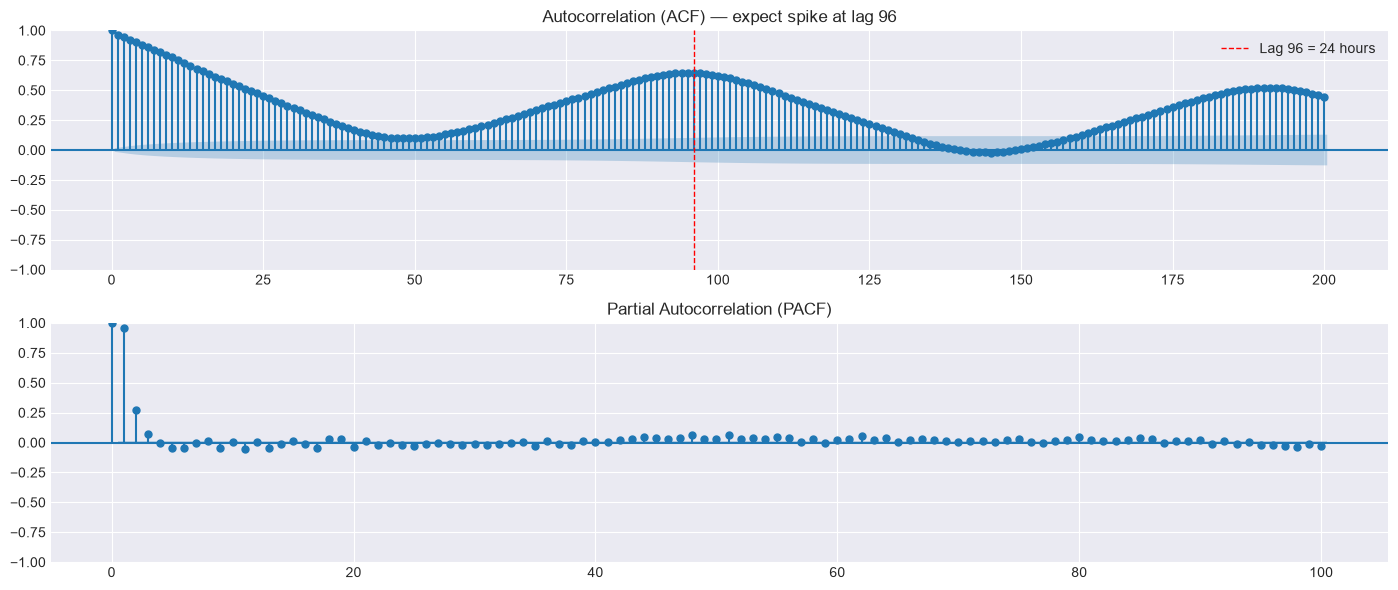

In [23]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

busy_15min = demand_clean.set_index('datetime')['busy'].resample('15min').mean().dropna()

fig, axes = plt.subplots(2, 1, figsize=(14, 6))

plot_acf(busy_15min, lags=200, ax=axes[0], alpha=0.05)
axes[0].axvline(96, color='red', ls='--', lw=1, label='Lag 96 = 24 hours')
axes[0].set_title('Autocorrelation (ACF) — expect spike at lag 96')
axes[0].legend()

plot_pacf(busy_15min, lags=100, ax=axes[1], alpha=0.05, method='ywm')
axes[1].set_title('Partial Autocorrelation (PACF)')

plt.tight_layout(); plt.show()

Reference screenshots of the ACF and PACF plots from my first run (kept so the written interpretation below has something visual to anchor to even without re-running):

ACF (Autocorrelation Function) measures how correlated a time series is with its own past values at different time lags.“Demand now correlates with demand 2 steps ago” Knowing what happened k steps ago helps predict what’s happening now — and therefore, knowing what’s happening now helps predict k steps into the future. ACF analysis confirmed strong daily seasonality (r=0.7 at 24-hour lag), with minimum correlation at 12 hours reflecting the overnight-peak/afternoon-trough cycle, supporting a 24-hour lookback window for LSTM modeling.




# 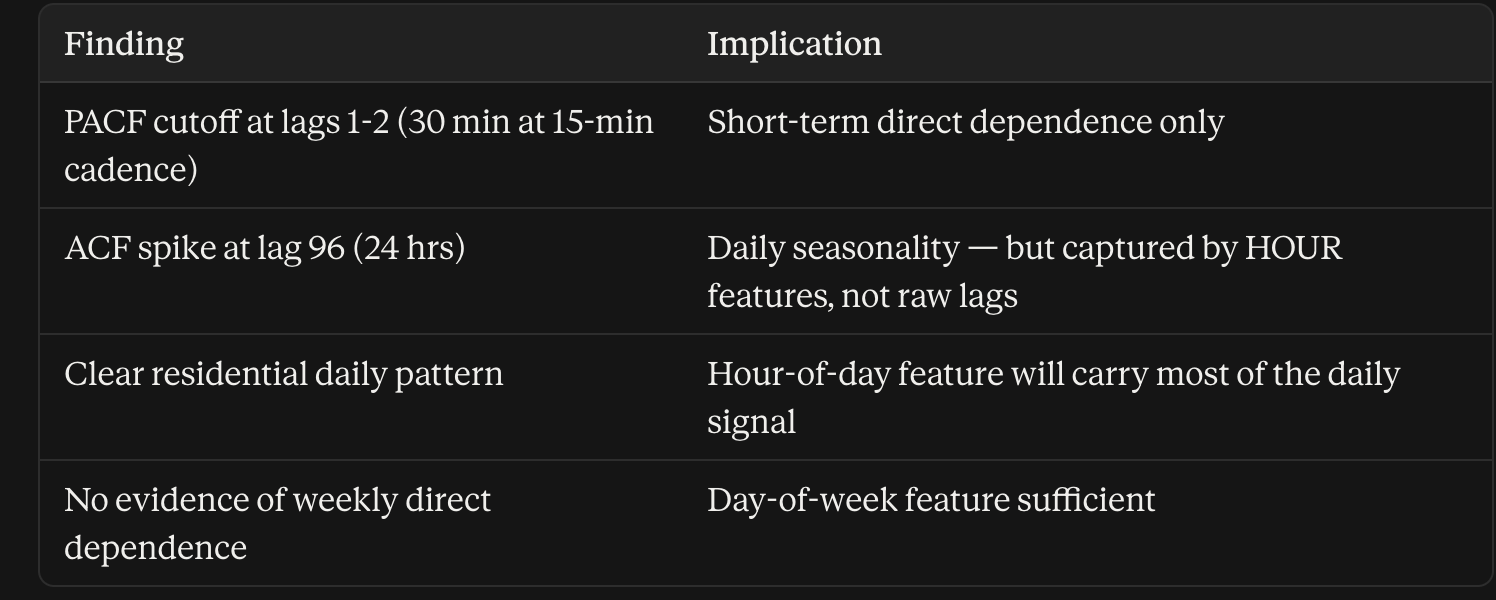

LSTM input per timestep:
1. Recent busy values (short lookback — PACF confirms)
2.  Time features (hour, day-of-week — captures daily/weekly cycles)

**Observed:**

| Plot | Pattern |
|------|---------|
| ACF | Starts at 1.0, decays slowly for the first ~10 lags, dips to a **minimum (slightly negative) around lag 50** (12 hours), climbs back up to a **spike of ~0.7 at lag 96** (24 hours) |
| PACF | Significant spikes only at **lag 1 and lag 2**; everything from lag 3 onward sits inside the 95% confidence band |

**Insight — reconciling the two plots:**

- ACF spike at lag 96 confirms the daily seasonality from Section 8.
- PACF has **no** spike at lag 96 → the series does not have a *direct* 24-hour dependence. The ACF
  spike is driven by a **common cause**: both time points share the same hour of day. The daily
  cycle is a schedule, not a memory.
- PACF spikes only at lags 1–2 → the *only* direct dependence in the raw signal is on the previous
  ~30 minutes (short-term momentum).
- Classical pattern: PACF cutoff at 2 is the AR(2) signature.

**Modeling implications carried into the next notebook:**

1. **Lookback window** does not need to be 24 hours of raw history. ~2 hours is a defensible default
   (short-direct dependence + modest buffer). Ablation on {6, 24, 72, 288} steps will test this.
2. **Hour-of-day features (sin / cos)** are the right way to let the model know "it's 2 AM."
3. **Seasonal-naive** (predict `busy_t` = `busy_{t-96}`) is a strong baseline — if an LSTM barely beats
   it, the extra complexity isn't justified.

**Next:** persist the cleaned series to disk and move on to feature engineering and models.


## 10. Summary and Save Cleaned Data

### What the data taught me

| Area | Finding |
|------|---------|
| Time integrity | Perfect 5-min grid, no duplicates, no index gaps |
| Missing data | 5 sensor-outage blocks (992 rows). Hybrid rule: LOCF < 6 h, drop ≥ 6 h |
| Oct 21–24 | Sensor anomaly (volatility ~10× normal) — dropped |
| Daily pattern | Residential overnight charging — peak 00–05, trough 14–16 |
| Day of week | Weekday ≈ weekend; the daily shape dominates |
| Month | No seasonal drift across Sep → Feb |
| ACF | Spike at lag 96 — daily seasonality |
| PACF | Significant only at lags 1–2 — short-term direct dependence only |

### Decisions carried into the next notebook

| Decision | Value |
|----------|-------|
| Target | `busy` (count of occupied stalls, 0–36) |
| Cadence | 5 minutes (raw, for real-time stall-availability use case) |
| Lookback (default) | 24 steps = 2 hours (PACF-informed, with buffer) |
| Horizon | 12 steps = 1 hour ahead |
| Must-have features | hour-of-day sin/cos, day-of-week sin/cos |
| Train/val/test | Chronological, never random |
| Baselines required | Persistence, seasonal-naive, AR(2) |
| Ablations planned | Lookback size, feature groups, attention on/off |


In [25]:
# Save cleaned data for the next notebook
import os
processed_dir = '/Users/Aishwarya/Aish Projects/Time series Pytorch/data'
os.makedirs(processed_dir, exist_ok=True)
output_path = f'{processed_dir}/demand_clean.csv'

cols_to_save = ['datetime', 'busy', 'idle', 'volume', 's_price', 'e_price',
                'fast_busy', 'fast_idle', 'slow_busy', 'slow_idle', 'duration']
demand_clean[cols_to_save].to_csv(output_path, index=False)

saved = pd.read_csv(output_path, parse_dates=['datetime'])
print("Cleaned data saved")
print("-"*40)
print(f"Path:        {output_path}")
print(f"Rows:        {len(saved):,}")
print(f"Date range:  {saved['datetime'].min()}  ->  {saved['datetime'].max()}")
print(f"Columns:     {list(saved.columns)}")
print(f"NaN check:   {saved.isna().sum().sum()}")
print(f"\nReady for 02_feature_engineering_and_models.ipynb")

Cleaned data saved
----------------------------------------
Path:        /Users/Aishwarya/Aish Projects/Time series Pytorch/data/demand_clean.csv
Rows:        51,191
Date range:  2022-09-01 00:00:00  ->  2023-02-28 23:55:00
Columns:     ['datetime', 'busy', 'idle', 'volume', 's_price', 'e_price', 'fast_busy', 'fast_idle', 'slow_busy', 'slow_idle', 'duration']
NaN check:   0

Ready for 02_feature_engineering_and_models.ipynb
